In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/ml_projects/heart.csv')

In [ ]:
df = data
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [ ]:
df.shape

(303, 14)

In [ ]:
df.iloc[200:210]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
200,44,1,0,110,197,0,0,177,0,0.0,2,1,2,0
201,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
202,58,1,0,150,270,0,0,111,1,0.8,2,0,3,0
203,68,1,2,180,274,1,0,150,1,1.6,1,0,3,0
204,62,0,0,160,164,0,0,145,0,6.2,0,3,3,0
205,52,1,0,128,255,0,1,161,1,0.0,2,1,3,0
206,59,1,0,110,239,0,0,142,1,1.2,1,1,3,0
207,60,0,0,150,258,0,0,157,0,2.6,1,2,3,0
208,49,1,2,120,188,0,1,139,0,2.0,1,3,3,0
209,59,1,0,140,177,0,1,162,1,0.0,2,1,3,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


In [ ]:
x = df.drop('target', axis=1)
y = df['target']

In [ ]:
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


In [ ]:
y

,target
0,1
1,1
2,1
3,1
4,1
...,...
298,0
299,0
300,0
301,0


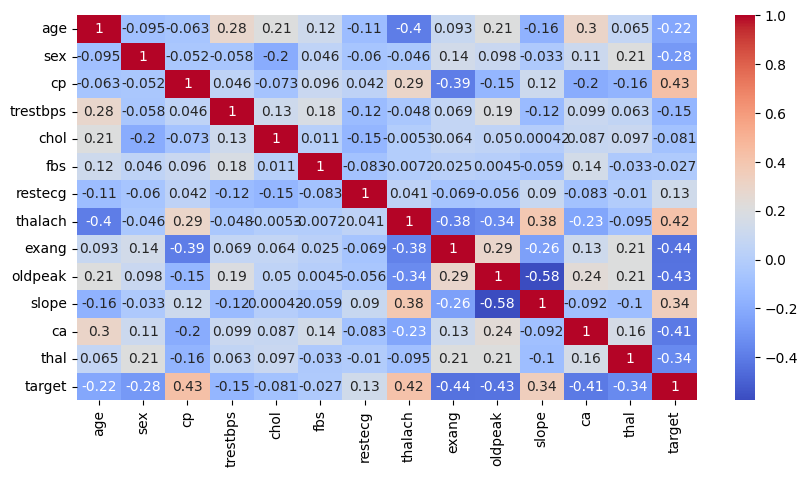

In [ ]:
corr = df.corr()
plt.figure(figsize=(10, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [ ]:
col = df.columns

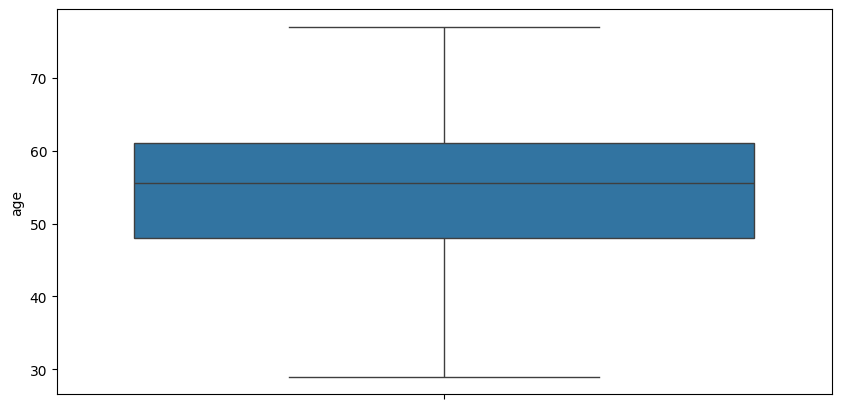

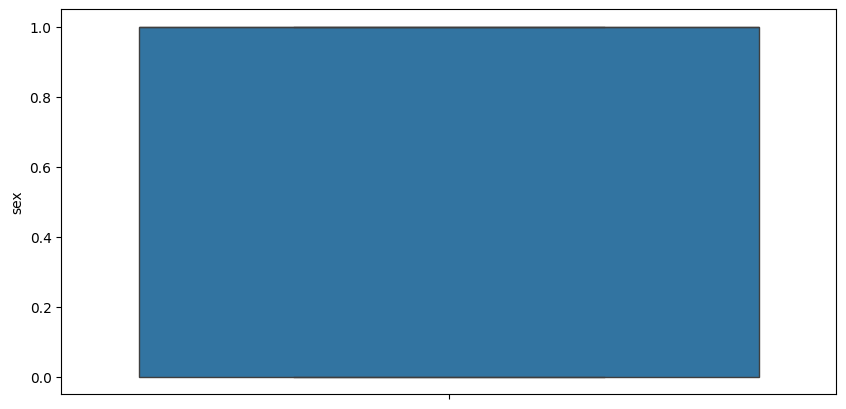

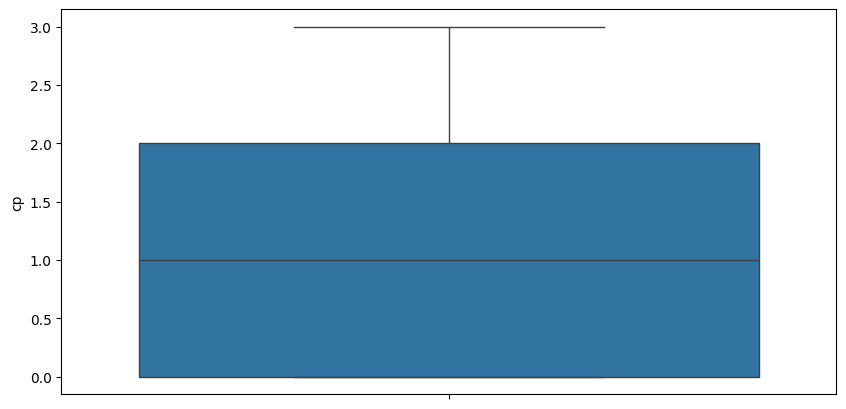

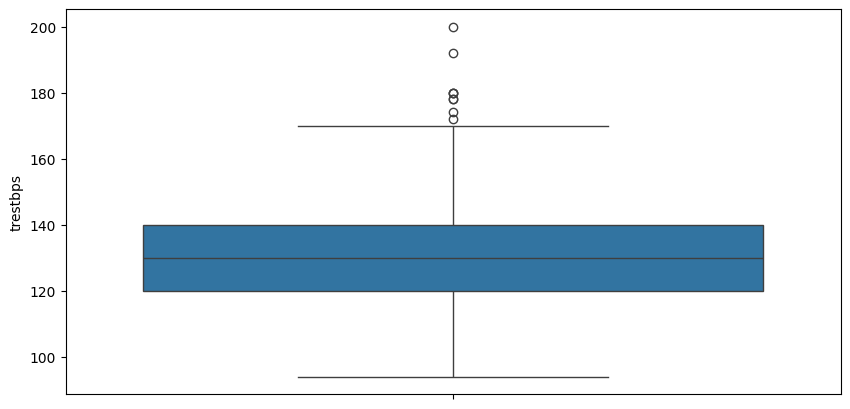

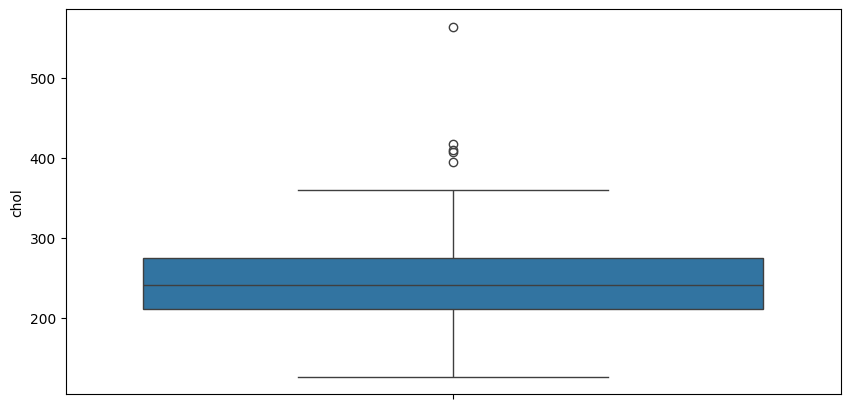

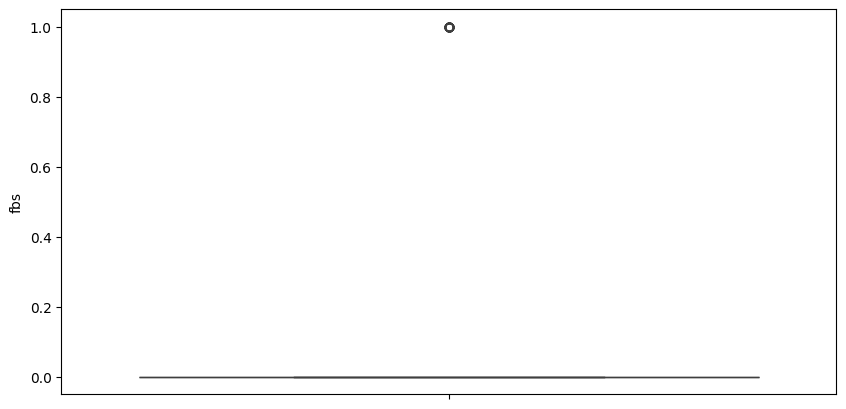

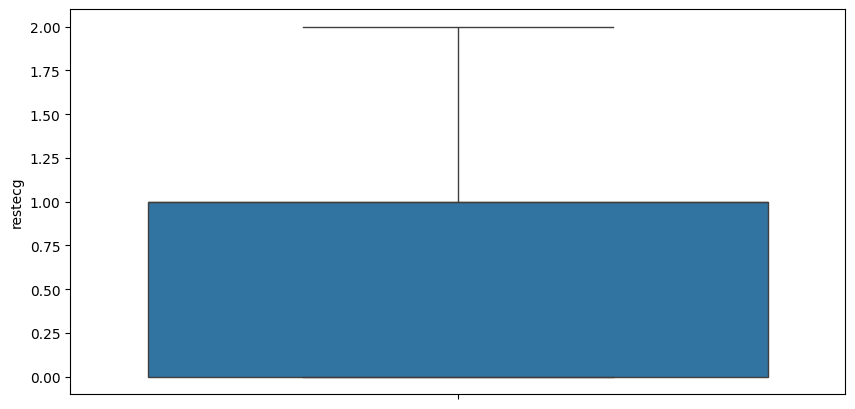

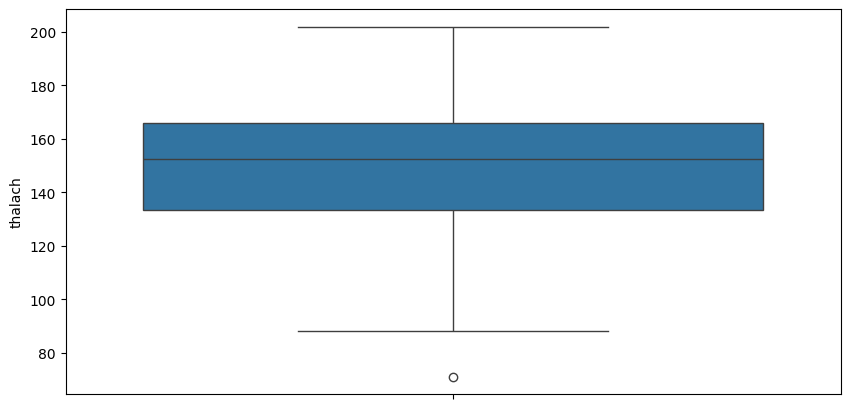

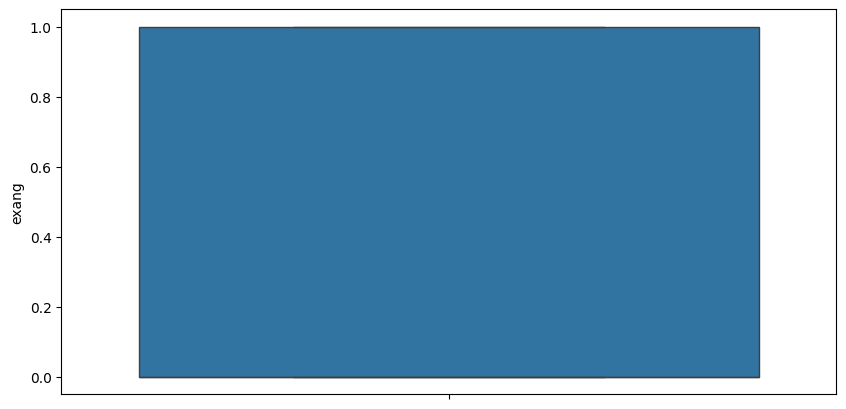

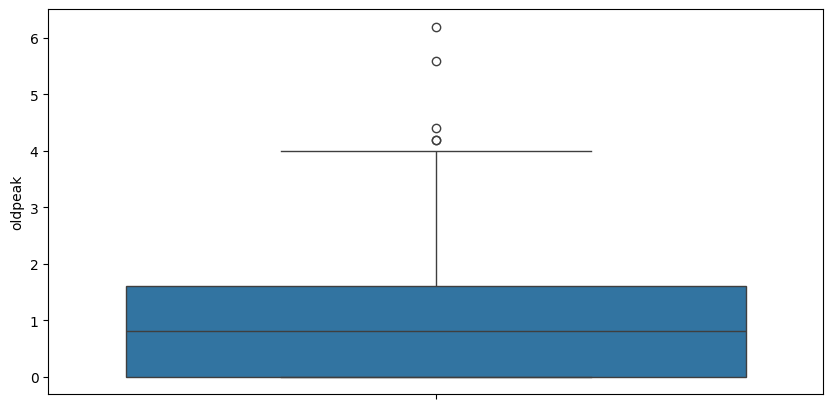

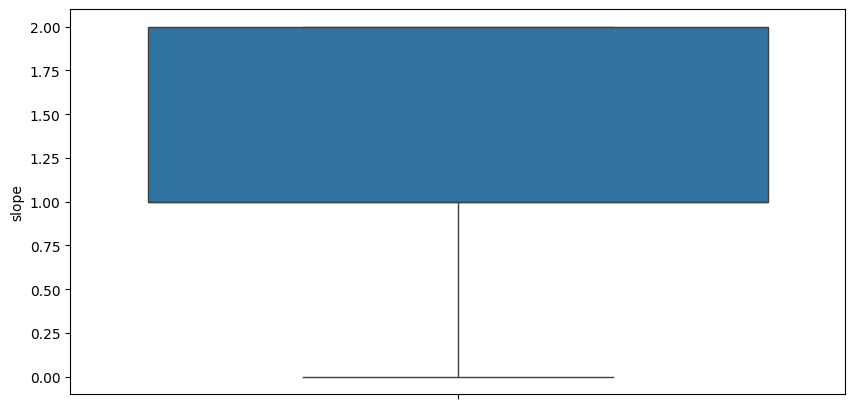

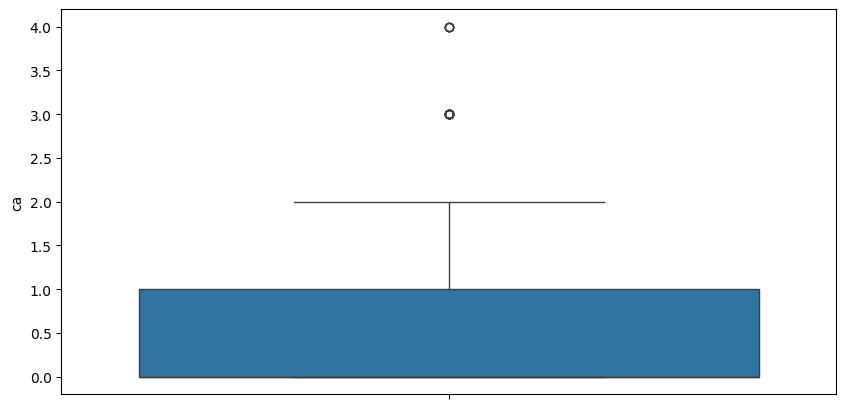

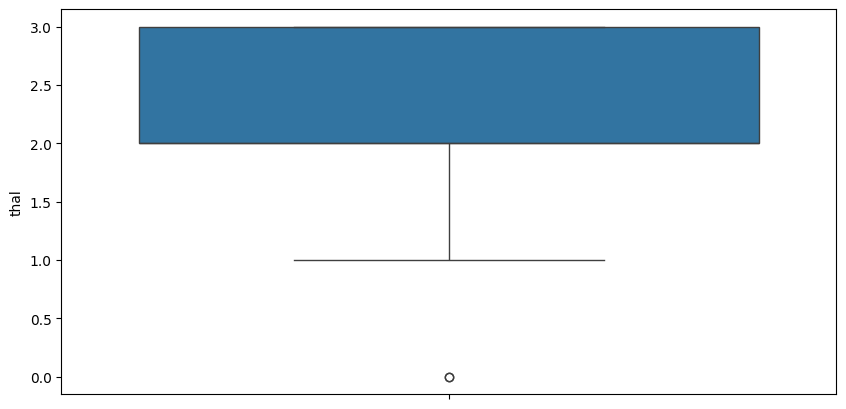

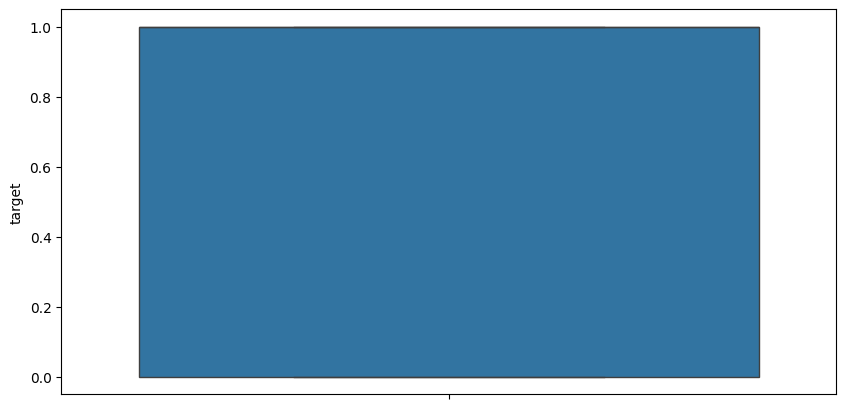

In [ ]:
for i in col:
  plt.figure(figsize=(10, 5))
  sns.boxplot(df[i])
  plt.show()

In [ ]:
model_a = LogisticRegression(max_iter=2000)
model_b = RandomForestClassifier(n_estimators=300,random_state=42,max_depth=5)
model_c = DecisionTreeClassifier(max_depth=5)

In [ ]:
xtest,xtrain,ytest,ytrain = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
model_a.fit(xtrain, ytrain)

LogisticRegression(max_iter=2000)

In [ ]:
model_b.fit(xtrain, ytrain)

RandomForestClassifier(max_depth=5, n_estimators=300, random_state=42)

In [ ]:
model_c.fit(xtrain, ytrain)

DecisionTreeClassifier(max_depth=5)

In [ ]:
model_a_pred = model_a.predict(xtest)
model_b_pred = model_b.predict(xtest)
model_c_pred = model_c.predict(xtest)

In [ ]:
round(accuracy_score(ytest, model_a_pred), 4)*100

79.25

In [ ]:
round(accuracy_score(ytest, model_b_pred), 4)*100

81.74

In [ ]:
round(accuracy_score(ytest, model_c_pred), 4)*100

75.92999999999999